In [40]:
import numpy as np
import pandas as pd

# Load the Iris dataset from your CSV file
df = pd.read_csv(r"C:\Users\nithy\OneDrive\Desktop\nithya\datheon\iris.csv")

# Display the first five rows
print(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the column names
print(df.columns.tolist())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Dataset shape: (150, 5)
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [4]:
# Separate input features and target
X = df[[
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]]

y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSpecies counts:")
print(y.value_counts())

Features shape: (150, 4)
Target shape: (150,)

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [8]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [28]:
print("Data types and non-null counts:")
display(df.info())
print("\\nSummary statistics:")
display(df.describe().T)
print("\\nMissing values per column:")
display(df.isna().sum())

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


None

\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


\nMissing values per column:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

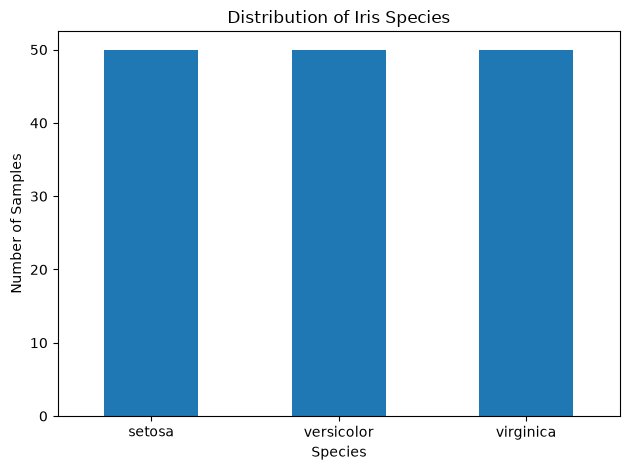

In [11]:
import matplotlib.pyplot as plt

df["species"].value_counts().plot(kind="bar")
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable


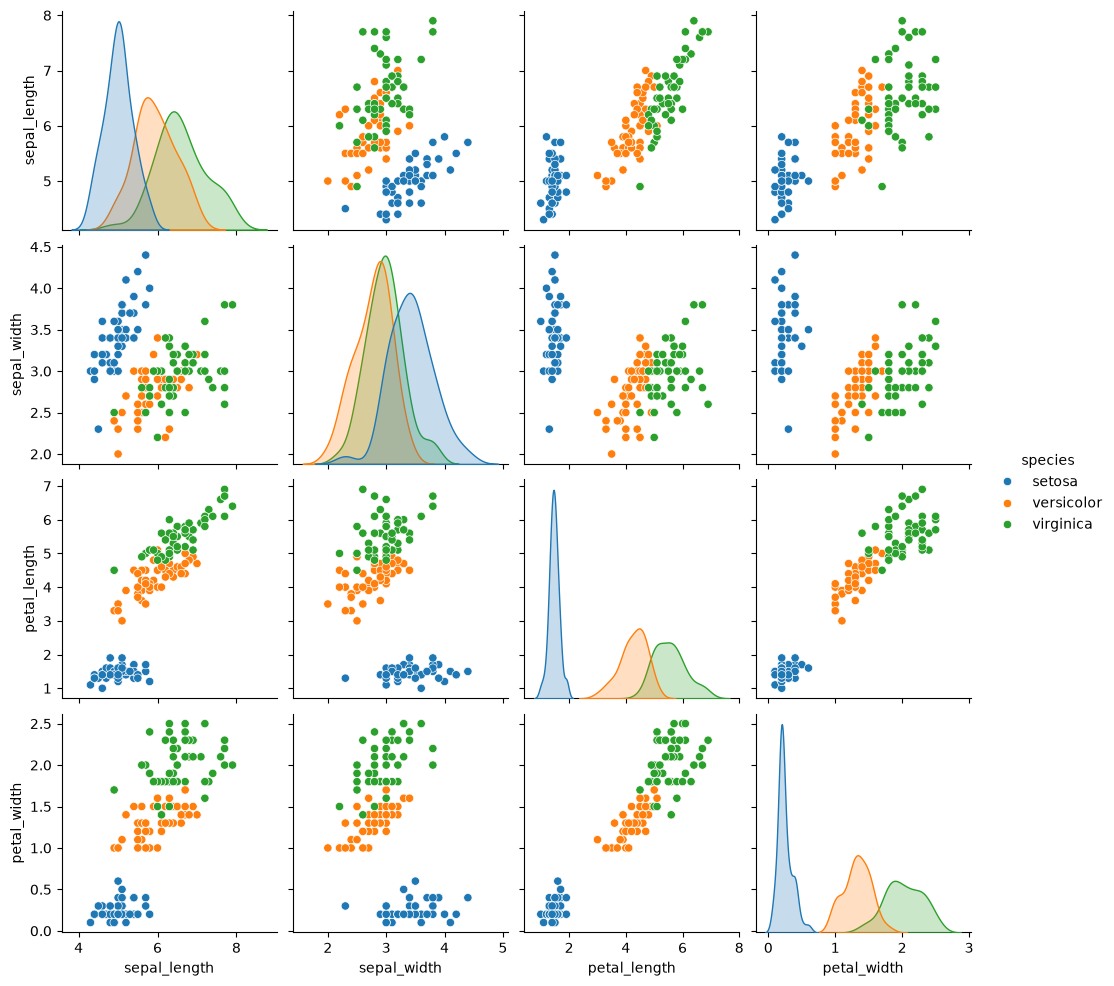

In [14]:
import seaborn as sns

sns.pairplot(df, hue="species")
plt.show()

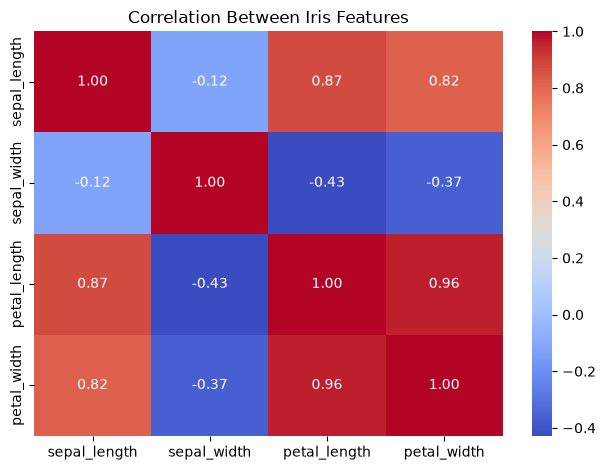

In [15]:
correlation = df.select_dtypes(include="number").corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining species counts:")
print(y_train.value_counts())

print("\nTesting species counts:")
print(y_test.value_counts())

Training samples: 120
Testing samples: 30

Training species counts:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing species counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("\nTraining class counts:")
display(y_train.value_counts().sort_index().rename("count").to_frame())
print("Test class counts:")
display(y_test.value_counts().sort_index().rename("count").to_frame())

Training samples: 120
Test samples: 30

Training class counts:


,count
species,
setosa,40
versicolor,40
virginica,40


Test class counts:


,count
species,
setosa,10
versicolor,10
virginica,10


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [30]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=4))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="macro"
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [34]:
from sklearn.metrics import classification_report

class_names = ["setosa", "versicolor", "virginica"]

for name, y_pred in predictions.items():
    print(f"\n{'=' * 65}\n{name} — Classification Report")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_names,
        target_names=class_names,
        zero_division=0
    ))



Logistic Regression — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



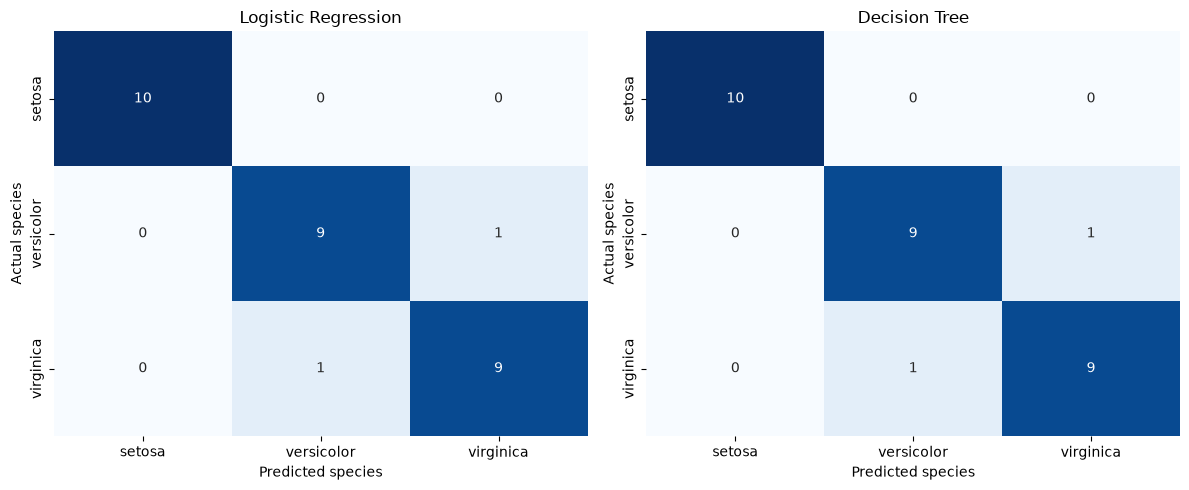

In [37]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["setosa", "versicolor", "virginica"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["setosa", "versicolor", "virginica"],
        yticklabels=["setosa", "versicolor", "virginica"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")

plt.tight_layout()
plt.show()


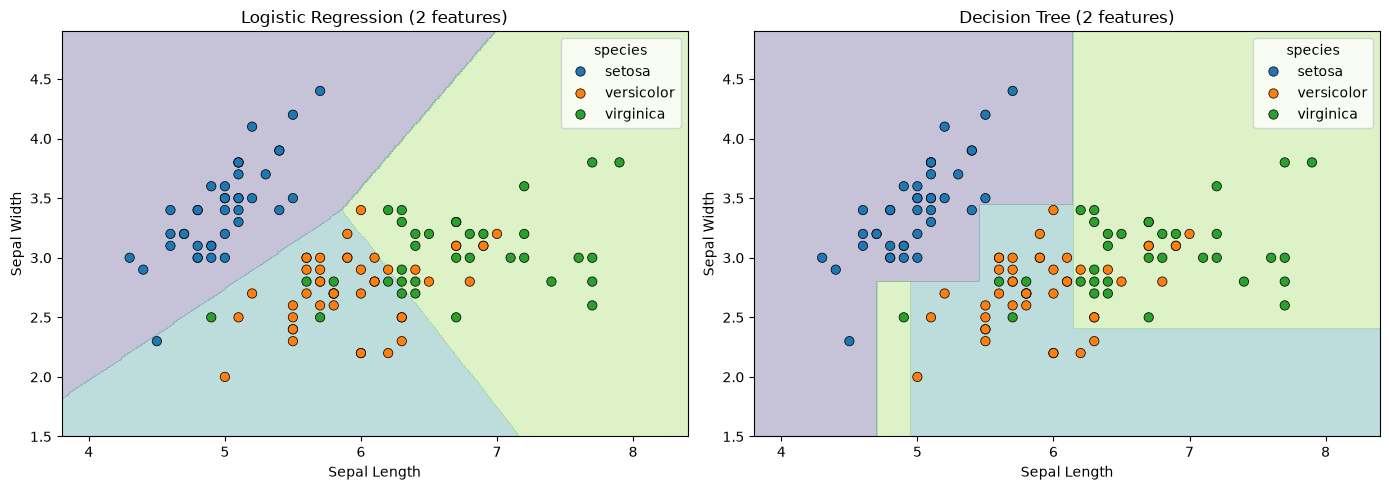

In [41]:
# Select two features for visualization
X_2d = X[["sepal_length", "sepal_width"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Models for 2D visualization
boundary_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),
    "Decision Tree (2 features)": DecisionTreeClassifier(
        max_depth=4,
        random_state=RANDOM_STATE
    )
}

# Create a grid of feature values
x_min = X_2d["sepal_length"].min() - 0.5
x_max = X_2d["sepal_length"].max() + 0.5
y_min = X_2d["sepal_width"].min() - 0.5
y_max = X_2d["sepal_width"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "sepal_length": xx.ravel(),
    "sepal_width": yy.ravel()
})

class_names = ["setosa", "versicolor", "virginica"]
class_to_num = {label: i for i, label in enumerate(class_names)}

# Plot decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X2_train, y2_train)

    grid_pred = model.predict(grid)
    Z = np.array([
        class_to_num[label] for label in grid_pred
    ]).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.3,
        levels=np.arange(-0.5, 3.5, 1),
        cmap="viridis"
    )

    sns.scatterplot(
        data=pd.DataFrame({
            "sepal_length": X2_train["sepal_length"],
            "sepal_width": X2_train["sepal_width"],
            "species": y2_train
        }),
        x="sepal_length",
        y="sepal_width",
        hue="species",
        hue_order=class_names,
        s=45,
        edgecolor="black",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Sepal Length")
    ax.set_ylabel("Sepal Width")

plt.tight_layout()
plt.show()


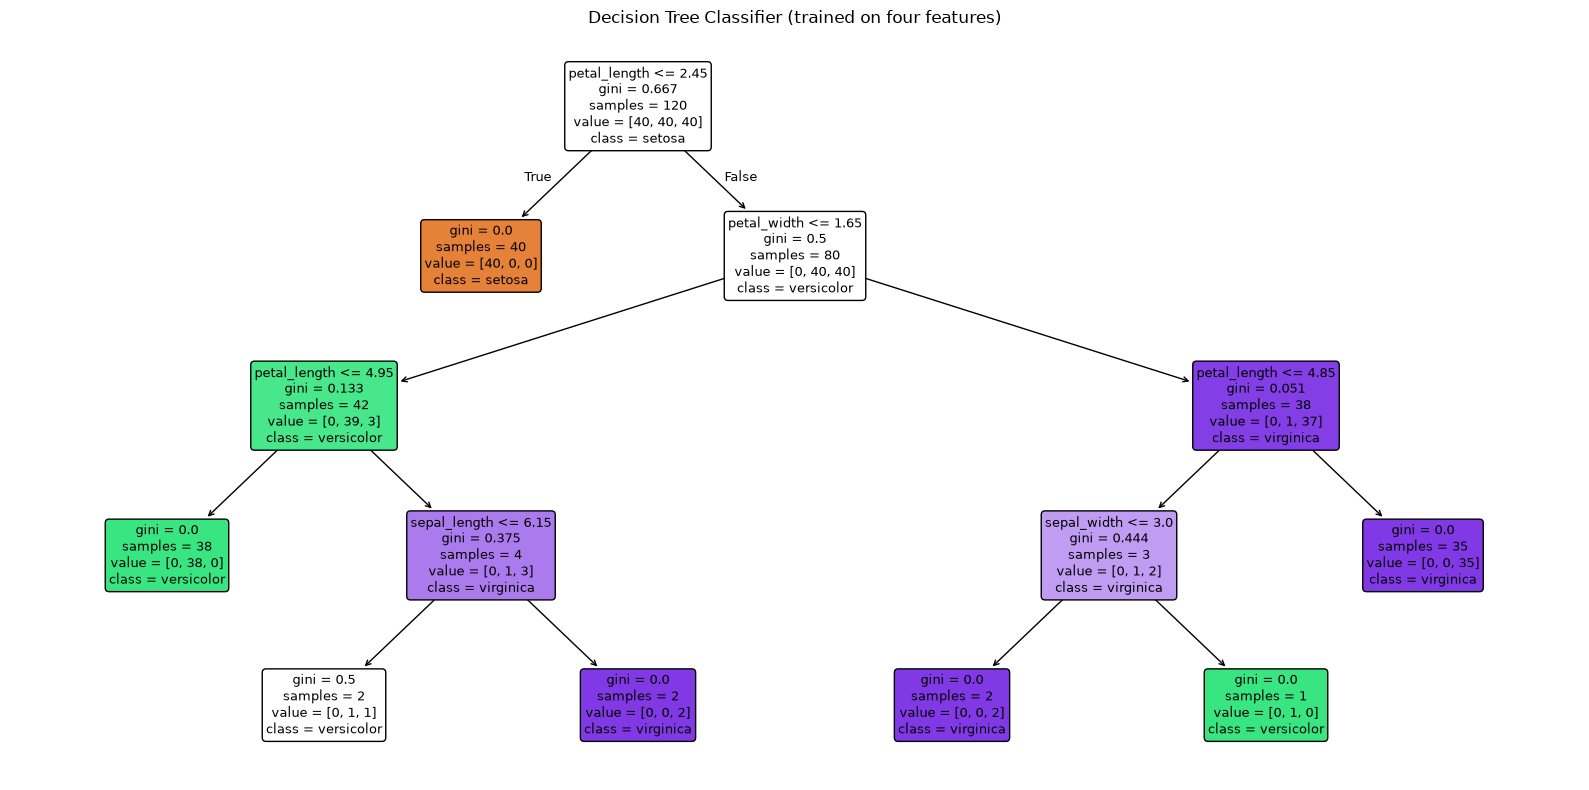

In [45]:
from sklearn.tree import plot_tree
tree_model = models["Decision Tree"].named_steps["classifier"]

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=X.columns.tolist(),
    class_names=["setosa", "versicolor", "virginica"],
    filled=True,
    rounded=True,
    proportion=False,
    fontsize=9
)

plt.title("Decision Tree Classifier (trained on four features)")
plt.tight_layout()
plt.show()
